In [1]:
# Sistematização - Métodos Matemáticos
# Tema: Analisador e Filtro de Sinais
# Aluno: Rodrigo Pepato
# Sinal escolhido: Sintético

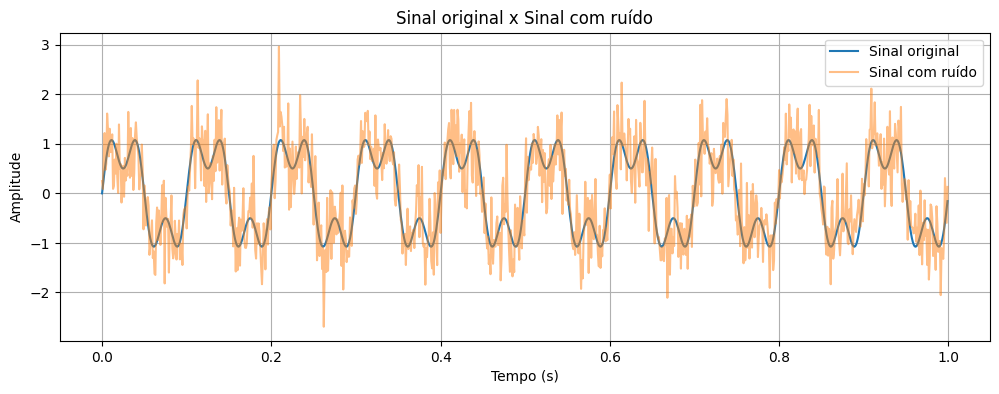

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Taxa de amostragem
fs = 1000

# Tempo de 1 segundo
t = np.arange(0, 1, 1/fs)

# Duas ondas com frequências diferentes
sinal_original = np.sin(2*np.pi*10*t) + 0.5*np.sin(2*np.pi*30*t)

# Gerar ruído aleatório
np.random.seed(42)
ruido = 0.5 * np.random.randn(len(t))

# Misturar o sinal com o ruído
sinal_ruidoso = sinal_original + ruido

# Exibir os sinais
plt.figure(figsize=(12, 4))
plt.plot(t, sinal_original, label="Sinal original")
plt.plot(t, sinal_ruidoso, label="Sinal com ruído", alpha=0.5)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Sinal original x Sinal com ruído")
plt.legend()
plt.grid()
plt.show()

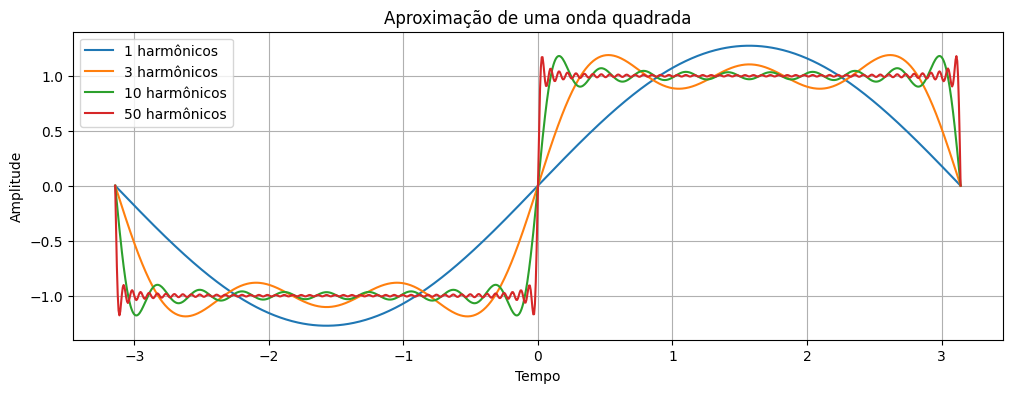

In [3]:
# Aproximação de uma onda quadrada pela Série de Fourier

t = np.linspace(-np.pi, np.pi, 1000)

plt.figure(figsize=(12, 4))

for N in [1, 3, 10, 50]:
    y = np.zeros_like(t)

    for k in range(N):
        n = 2*k + 1
        y += (4 / np.pi) * np.sin(n*t) / n

    plt.plot(t, y, label=f"{N} harmônicos")

plt.title("Aproximação de uma onda quadrada")
plt.xlabel("Tempo")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

### Etapa 1 — Série de Fourier

Nesta etapa, utilizamos a Série de Fourier para aproximar uma onda quadrada por meio da soma de funções senoidais.

Foram realizadas aproximações utilizando 1, 3, 10 e 50 harmônicos. Observamos que, quanto maior a quantidade de harmônicos, mais a função se aproxima da forma quadrada.

Nas regiões de descontinuidade, aparecem oscilações conhecidas como fenômeno de Gibbs, que persistem mesmo com o aumento do número de harmônicos.


## Coeficientes da Série de Fourier

Para uma onda quadrada de período $2\pi$, com amplitude +1 e -1, os coeficientes são:

- **Coeficiente constante:** $a_0 = 0$
- **Coeficientes de cosseno:** $a_n = 0$
- **Coeficientes de seno:**

$$
b_n = \begin{cases}
\frac{4}{n\pi}, & n \text{ ímpar} \\
0, & n \text{ par}
\end{cases}
$$

Assim, a Série de Fourier é:

$$
f(t)=\frac{4}{\pi}\left(\sin t+\frac{\sin 3t}{3}+\frac{\sin 5t}{5}+\cdots\right)
$$

### Forma complexa

$$
f(t)=\sum_{n=-\infty}^{\infty}c_n e^{int}
$$

Onde:

$$
c_n = \begin{cases}
\frac{2}{i\pi n}, & n \text{ ímpar} \\
0, & n \text{ par}
\end{cases}
$$

Esses coeficientes mostram que a onda quadrada pode ser representada pela soma de harmônicos de frequências ímpares.
  

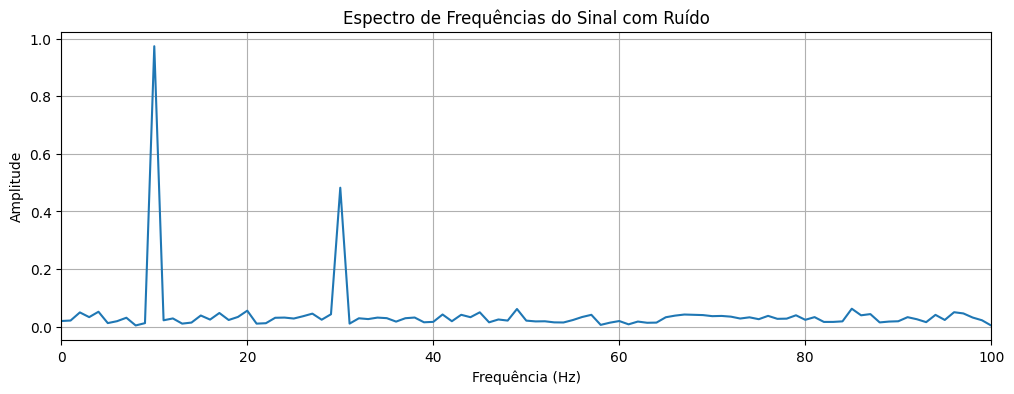

In [4]:
from scipy.fft import rfft, rfftfreq

# Recuperar o sinal com ruído
N = len(sinal_ruidoso)

# Aplicar a Transformada de Fourier
fft_sinal = rfft(sinal_ruidoso)

# Calcular as frequências
frequencias = rfftfreq(N, 1/fs)

# Calcular a amplitude
amplitude = 2 * np.abs(fft_sinal) / N

# Gerar o gráfico
plt.figure(figsize=(12, 4))
plt.plot(frequencias, amplitude)

plt.title("Espectro de Frequências do Sinal com Ruído")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 100)
plt.grid()
plt.show()

### Etapa 2 — Transformada de Fourier (FFT)

Utilizamos a Transformada Rápida de Fourier (FFT) para analisar as frequências presentes no sinal sintético com ruído.

O gráfico apresenta dois picos principais, em 10 Hz e 30 Hz, correspondentes às frequências utilizadas na geração do sinal original.

As pequenas amplitudes distribuídas pelo espectro representam o ruído adicionado.

A taxa de amostragem utilizada foi de 1000 Hz. Portanto, pelo teorema de Nyquist, a frequência máxima que pode ser representada sem aliasing é de 500 Hz.

A análise demonstra que a Transformada de Fourier permite identificar as frequências que compõem um sinal, mesmo quando ele apresenta interferências no domínio do tempo.

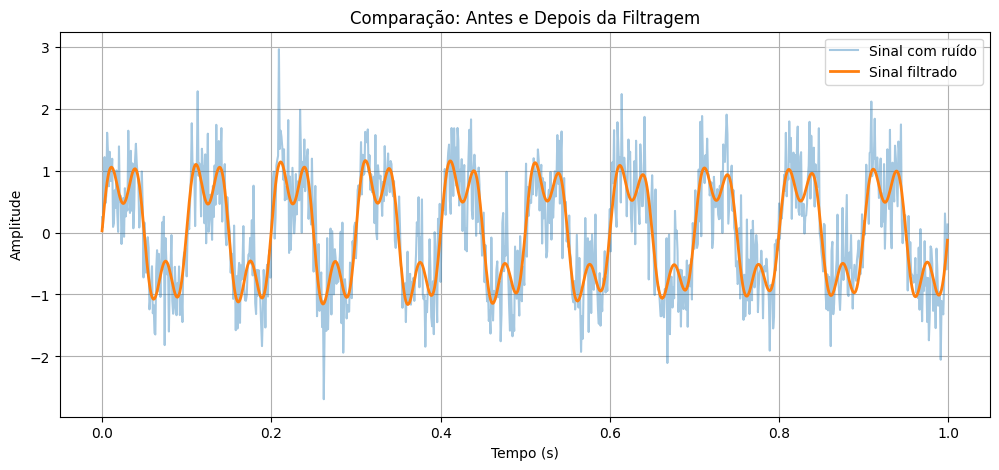

In [5]:
from scipy.fft import irfft

# Criar uma cópia do espectro
fft_filtrada = fft_sinal.copy()

# Manter apenas as frequências próximas de 10 Hz e 30 Hz
mascara = (
    (np.abs(frequencias - 10) <= 1) |
    (np.abs(frequencias - 30) <= 1)
)

fft_filtrada[~mascara] = 0

# Reconstruir o sinal com a Transformada Inversa
sinal_filtrado = irfft(fft_filtrada, n=N)

# Comparar os sinais
tempo = np.arange(N) / fs

plt.figure(figsize=(12, 5))

plt.plot(tempo, sinal_ruidoso,
         label="Sinal com ruído", alpha=0.4)

plt.plot(tempo, sinal_filtrado,
         label="Sinal filtrado", linewidth=2)

plt.title("Comparação: Antes e Depois da Filtragem")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

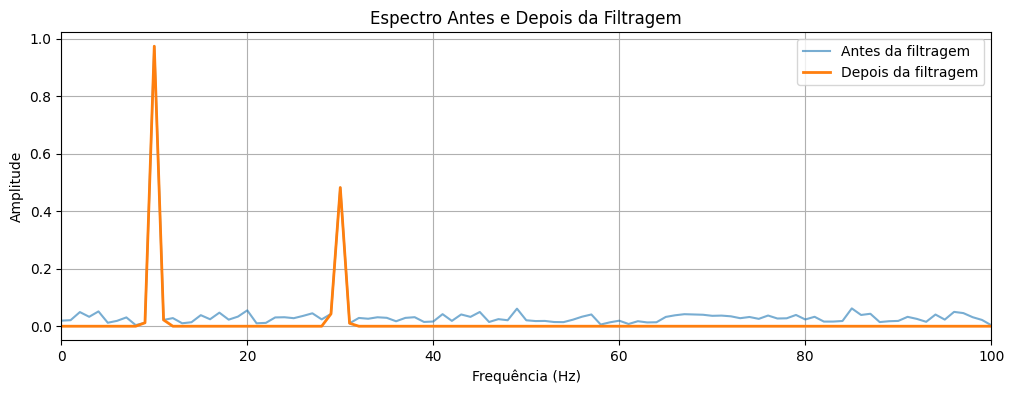

In [6]:
# Calcular o espectro após a filtragem
amplitude_filtrada = 2 * np.abs(fft_filtrada) / N

plt.figure(figsize=(12, 4))

plt.plot(frequencias, amplitude,
         label="Antes da filtragem", alpha=0.6)

plt.plot(frequencias, amplitude_filtrada,
         label="Depois da filtragem", linewidth=2)

plt.title("Espectro Antes e Depois da Filtragem")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 100)
plt.legend()
plt.grid()
plt.show()

### Etapa 3 — Filtragem e reconstrução do sinal

Nesta etapa, aplicamos um filtro seletivo no domínio da frequência para remover o ruído do sinal sintético.

O filtro preservou as componentes próximas de 10 Hz e 30 Hz, eliminando as demais frequências.

Em seguida, utilizamos a Transformada Inversa de Fourier (IFFT) para reconstruir o sinal no domínio do tempo.

Ao comparar os gráficos, observamos que o sinal filtrado apresentou uma forma mais suave e semelhante ao sinal original.

No espectro de frequências, verificamos que os dois picos principais foram preservados, enquanto as componentes indesejadas foram removidas.

Portanto, a filtragem foi eficaz para recuperar as frequências de interesse do sinal sintético.

Função de transferência H(s):
  251.327412287183  
────────────────────
s + 251.327412287183


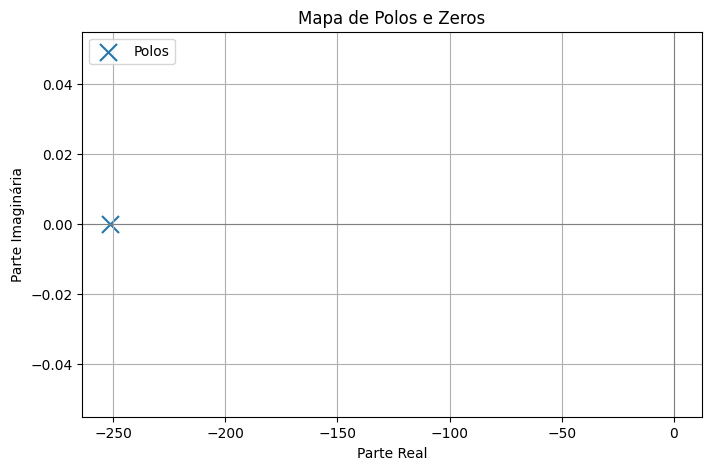

Polos: [-251.32741229]
Zeros: []


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sympy as sp

# Definir a variável de Laplace
s = sp.symbols('s')

# Frequência de corte: 40 Hz
fc = 40
wc = 2 * np.pi * fc

# Função de transferência H(s)
H = wc / (s + wc)

print("Função de transferência H(s):")
sp.pprint(H)

# Criar o sistema linear
sistema = signal.TransferFunction([wc], [1, wc])

# Obter polos e zeros
zeros, polos, ganho = signal.tf2zpk([wc], [1, wc])

# Gráfico de polos e zeros
plt.figure(figsize=(8, 5))

plt.scatter(np.real(polos), np.imag(polos),
            marker='x', s=150, label="Polos")

plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)

plt.title("Mapa de Polos e Zeros")
plt.xlabel("Parte Real")
plt.ylabel("Parte Imaginária")
plt.legend()
plt.grid()
plt.show()

print("Polos:", polos)
print("Zeros:", zeros)

### Etapa 4 — Transformada de Laplace e análise de estabilidade

Nesta etapa, utilizamos um filtro passa-baixa RC de primeira ordem como modelo de sistema linear contínuo.

Sua função de transferência, obtida pela Transformada de Laplace, considerando condições iniciais nulas, é:

$$
H(s)=\frac{251,33}{s+251,33}
$$

O mapa de polos e zeros apresenta um único polo em aproximadamente -251,33 e nenhum zero finito.

Como o polo está localizado no semiplano esquerdo do plano complexo, o sistema é estável.

A frequência de corte do filtro é de 40 Hz. Isso significa que frequências abaixo desse valor sofrem menor atenuação, enquanto frequências acima são progressivamente atenuadas.

Relacionando com a Etapa 2, as frequências de 10 Hz e 30 Hz estão abaixo da frequência de corte e, portanto, são parcialmente preservadas.

O filtro RC é utilizado como modelo teórico para estudar a estabilidade e a resposta em frequência. Ele não é idêntico ao filtro seletivo aplicado na Etapa 3.

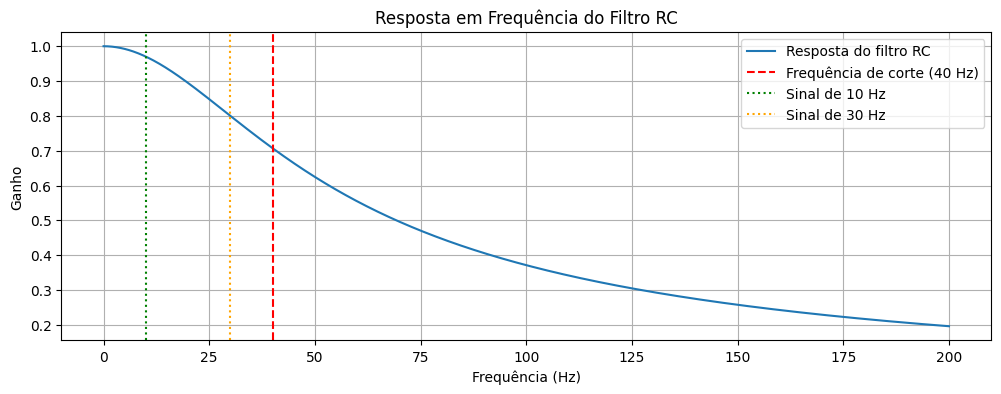

In [8]:
# Calcular a resposta em frequência do filtro RC
frequencias_rc = np.linspace(0, 200, 1000)

w = 2 * np.pi * frequencias_rc
_, resposta = signal.freqresp(sistema, w=w)

# Calcular a amplitude da resposta
ganho = np.abs(resposta)

# Gerar o gráfico
plt.figure(figsize=(12, 4))

plt.plot(frequencias_rc, ganho, label="Resposta do filtro RC")

plt.axvline(40, color="red", linestyle="--",
            label="Frequência de corte (40 Hz)")

plt.axvline(10, color="green", linestyle=":",
            label="Sinal de 10 Hz")

plt.axvline(30, color="orange", linestyle=":",
            label="Sinal de 30 Hz")

plt.title("Resposta em Frequência do Filtro RC")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Ganho")
plt.legend()
plt.grid()
plt.show()

### Análise da resposta em frequência do filtro RC

O gráfico apresenta a resposta em frequência do filtro passa-baixa RC, com frequência de corte de 40 Hz.

Observamos que a frequência de 10 Hz apresenta ganho aproximado de 0,97, enquanto a frequência de 30 Hz apresenta ganho de 0,80.

Na frequência de corte de 40 Hz, o ganho é aproximadamente 0,707, correspondente a uma atenuação de -3 dB.

Acima de 40 Hz, o ganho diminui progressivamente, demonstrando a capacidade do filtro de atenuar componentes de frequências mais altas.

Esse comportamento está relacionado ao polo localizado em -251,33 no plano complexo, que determina a frequência de corte e a dinâmica do sistema.

Dessa forma, conectamos a análise de frequências realizada com Fourier ao comportamento de um sistema linear descrito pela Transformada de Laplace.

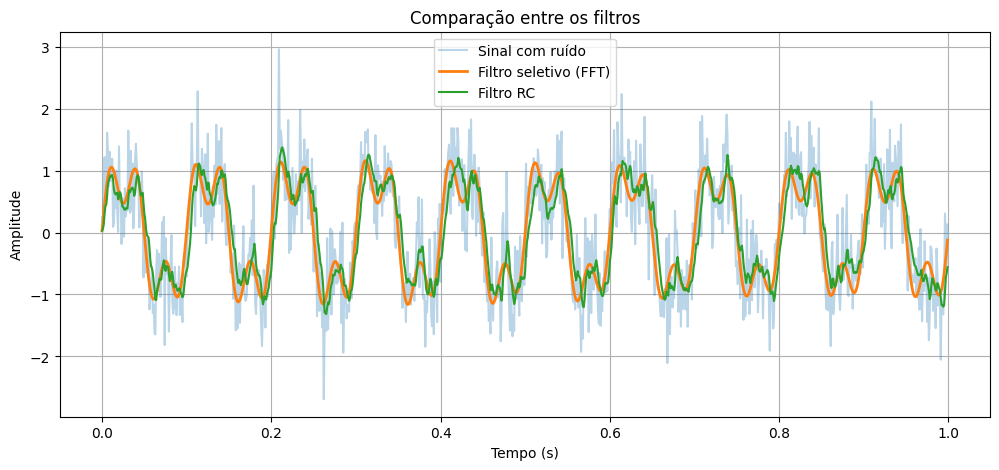

In [9]:
# Aplicar o filtro RC ao sinal com ruído
sistema_discreto = signal.cont2discrete(
    ([wc], [1, wc]), 1/fs, method="bilinear"
)

b = sistema_discreto[0].flatten()
a = sistema_discreto[1]

sinal_rc = signal.lfilter(b, a, sinal_ruidoso)

# Comparar os três sinais
plt.figure(figsize=(12, 5))

plt.plot(tempo, sinal_ruidoso,
         label="Sinal com ruído", alpha=0.3)

plt.plot(tempo, sinal_filtrado,
         label="Filtro seletivo (FFT)", linewidth=2)

plt.plot(tempo, sinal_rc,
         label="Filtro RC", linewidth=1.5)

plt.title("Comparação entre os filtros")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

### Comparação entre os filtros

Nesta análise, comparamos dois métodos de filtragem aplicados ao mesmo sinal sintético.

O filtro seletivo baseado na FFT apresentou melhor resultado na remoção do ruído, pois preservou apenas as frequências próximas de 10 Hz e 30 Hz.

O filtro RC também reduziu o ruído, principalmente nas frequências mais altas, porém manteve algumas oscilações indesejadas.

Essa diferença ocorre porque o filtro seletivo remove diretamente as componentes indesejadas do espectro, enquanto o filtro RC realiza uma atenuação gradual das frequências.

Concluímos que ambos os filtros são úteis, mas apresentam características e aplicações diferentes.